# 7.ParticulaPerturbada
### Física Electrónica - UTN FRA
*Cuaderno interactivo adaptado para Google Colab.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)


In [1]:
import matplotlib.pyplot as plt     # Paquete gráfico, se grafican las funciones a través de arrays.
from sympy import *                 # Paquete de algebraico, permite crear y manipular expresiones algebraicas. 
init_printing()                     # Da una buena presentación a la impresión de formulas creadas con sympy.
import numpy as np
x,x1,x2,l,V=symbols('x,x1,x2,l,V')


m_p=1
h_b=1
a1=1


def T(V,E,L):
    k=((2*m_p*E)**(0.5))/h_b
    q=((2*m_p*(V-E))**(0.5))/h_b
    G=((k**2-q**2)/(2*q*k))
    return 1/((np.cosh(q*L))**2+(G*np.sinh(q*L))**2)


def R1b(V,E,L,x):
    k=((2*m_p*E)**(0.5))/h_b
    q=((2*m_p*(V-E))**(0.5))/h_b
    A=((k**2+q**2)/(2*q*k))*np.sinh(q*L)
    B=np.cosh(q*L)
    C=((k**2-q**2)/(2*q*k))*np.sinh(q*L)
    X=(-A*C)/(B**2+C**2)
    Y=(A*B)/(B**2+C**2)
    return (a1**2)*((np.cos(k*x)-X*np.cos(k*x)-Y*np.sin(k*x))**2+(np.sin(k*x)+X*np.sin(k*x)-Y*np.cos(k*x))**2)

def R2b(V,E,L,x):
    k=((2*m_p*E)**(0.5))/h_b
    q=((2*m_p*(V-E))**(0.5))/h_b
    A=((k**2+q**2)/(2*q*k))*np.sinh(q*L)
    B=np.cosh(q*L)
    C=((k**2-q**2)/(2*q*k))*np.sinh(q*L)
    X=(-A*C)/(B**2+C**2)
    Y=(A*B)/(B**2+C**2)
    return (a1**2)*(((1-X)*np.cosh(q*x)-((Y*k)/q)*np.sinh(q*x))**2+(((k*(1+X))/q)*np.sinh(q*x)-Y*np.cosh(q*x))**2)

def R3b(V,E,L,x):
    k=((2*m_p*E)**(0.5))/h_b
    q=((2*m_p*(V-E))**(0.5))/h_b
    A=((k**2+q**2)/(2*q*k))*np.sinh(q*L)
    B=np.cosh(q*L)
    C=((k**2-q**2)/(2*q*k))*np.sinh(q*L)
    Z=B/(B**2+C**2)
    W=C/(B**2+C**2)
    return (a1**2)*((Z*np.cos(k*(x-L))-W*np.sin(k*(x-L)))**2+(Z*np.sin(k*(x-L))+W*np.cos(x-L))**2)


def BP(V,E,L):
    z4=np.linspace(-10*L,0,50)
    z5=np.linspace(0,L,50)
    z6=np.linspace(L,4*L,50)
    plt.plot(z4,R1b(V,E,L,z4))
    plt.plot(z5,R2b(V,E,L,z5))
    plt.plot(z6,R3b(V,E,L,z6))
    plt.plot([0,0,L,L],[0,V,V,0])
    plt.ylabel('Energía (Hartree)')
    plt.title('Transmisión={:f}'.format(T(V,E,L)))

# Funciones de onda perturbadas y no perturbadas 

def suma_pert(n):
    s=0
    iMax=n+5
    for m in list(range(1,n))+list(range(n+1,iMax)):
        s=s+(1/((n-m)*(n+m)))*integrate(sin((m*pi*x)/l)*sin((n*pi*x)/l),(x,x1*l,x2*l))*sin((m*pi*x)/l)
    return(s)

def Pn(n):
  m_p=1
  h_b=1
  s=(((2/l)**0.5)*(sin((n*pi*x)/l)))+(((4*V*m_p*l)/(h_b**2*pi**2))*suma_pert(n))
  return(s)  

def PnE(a,b,c,d,e,n):
  E=lambdify([x,x1,x2,l,V],Pn(n),np)
  return E(a,b,c,d,e) 
  # a=x, b=x1, c=x2, d=l, e=V  

def Fn(n):
  s=((2/l)**0.5)*(sin((n*pi*x)/l))
  return(s) 

def FnE(a,d,n):
  E=lambdify([x,l],Fn(n))
  return E(a,d)

def GFOp(b,c,d,e,n):
  x=np.linspace(0,d,100)
  y=np.linspace(b,b,100)
  z=np.linspace(c,c,100)
  w=np.linspace(d,d,100)
  s=np.linspace(e,e,100)
  plt.plot(x,PnE(x,y,z,w,s,n),color='blue',label='Función perturbada')
  plt.plot(x,FnE(x,d,n),color='orange',label='Función no perturbada')
  plt.title('$\psi${:d}'.format(n))
  plt.xlabel('Longitu de la caja')
  plt.legend()

def GFOd(b,c,d,e,n):
  x=np.linspace(0,d,100)
  y=np.linspace(b,b,100)
  z=np.linspace(c,c,100)
  w=np.linspace(d,d,100)
  s=np.linspace(e,e,100)
  plt.plot(x,PnE(x,y,z,w,s,n)**2,color='blue',label='Función de densidad perturbada')
  plt.plot(x,FnE(x,d,n)**2,color='orange',label='Función de densidad no perturbada')
  plt.title('$|\psi${:d}|²'.format(n))
  plt.xlabel('Longitu de la caja')
  plt.legend()

# **BARRERAS DE POTENCIAL**

Una barrera de potencial es una función de energía potencial con un máximo. En la siguiente figura se muestra una barrera rectángular de ancho $L=0.5$ y altura máxima $V_0=20$ hartree. De acuerdo con la mecánica clásica si una partícula con energía total $E$ menor que $V_0$ choca con la barrera, está no podrá pasar a través de la barrera y estará confinada del lado de la barrera en el que se encuentre inicialmente. En caso de que la partícula
cruzase la barrera su energía cinética $K=E-V=\frac{1}{2}mv^2$ sería negativa, lo que implicaría que la masa de la partícula es negativa o su velocidad toma un valor imaginario puro.

Text(0.5, 1.0, 'Barrera de potencial')

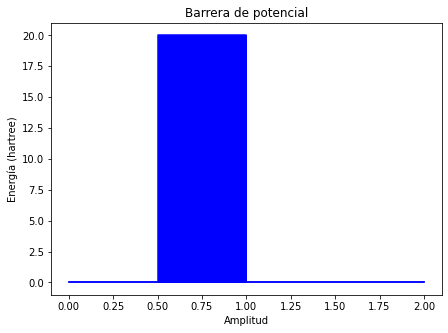

In [ ]:
#@title
# Gráfico de la barrera de potencial

l = 2    # ancho de la barrera en bohrs
V_0=20    # barrera de potencial
x1=0.25    # punto de inicio de barrera en proporcion de l
x2=0.5    # punto final de barrera en proporcion de l

plt.figure(figsize=(7,5))
plt.plot([0,x1*l,x1*l,x2*l,x2*l,l],[0,0,V_0,V_0,0,0],c='b')
plt.plot([0,l],[0,0],color='b')
plt.fill_between([x1*l,x2*l],[V_0,V_0],color='b')
plt.xlabel('Amplitud')
plt.ylabel('Energía (hartree)')
plt.title('Barrera de potencial')

En un sistema cuántico una partícula que se encuentra con una barrera no necesariamente regresa, la probabilidad de que salga por el otro lado es no nula, aún cuando no tenga energía cinética sufiente para remontar la barrera. A esta penetración de barrera se le llama $\textbf{tunelamiento}$.

Con el desarrollo de las técnicas experimentales, ha sido posible organizar nanoestructuras semiconductoras en la que los electrones de la banda de conducción experimentan cambios abruptos en el potencial cuando pasan de un material semiconductor a otro. Por ejemplo, si sobre un sustrato de $GaAs$ se hace crecer una capa de $Ga_{1-x}Al_xAs$ con espesor $L$ y sobre esta a su vez una capa de $GaAs$, se forma la heteroestructura $GaAs/Ga_{1-x}Al_xAs/GaAs$ en la que los electrones de la banda de conducción experimentan esencialmente una "barrera de potencial". En este sistema la altura dde la barrera $V$ esta relacionada con la concentración $x$ de Aluminio y con el gap de energía que separa las bandas de valencia y de conducción. Si la concentración es del $30\%$, la altura de la barrera de potencial en esta heteroestructura es $V=8.4523*10^{-3}$ Hartree.

En la siguiente figura se muestra el modulo de la función de onda para $E=6.6148*10^{-3}$ Hartree (menor que $V=8.4523*10^{-3}$ Hartree) y un ancho de barrera $L=6 \ nm=113.38 \ ua$. 

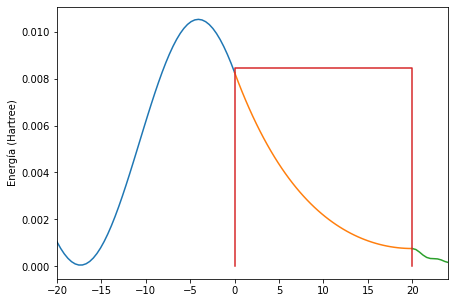

In [27]:
V=8.4523e-3
E=7e-3
L=20
a11=0.55e-1
k=((2*m_p*E)**(0.5))/h_b
q=((2*m_p*(V-E))**(0.5))/h_b
A=((k**2+q**2)/(2*q*k))*np.sinh(q*L)
B=np.cosh(q*L)
C=((k**2-q**2)/(2*q*k))*np.sinh(q*L)
X=(-A*C)/(B**2+C**2)
Y=(A*B)/(B**2+C**2)
Z=B/(B**2+C**2)
W=C/(B**2+C**2)

def R1(x):
    return (a11**2)*((np.cos(k*x)-X*np.cos(k*x)-Y*np.sin(k*x))**2+(np.sin(k*x)+X*np.sin(k*x)-Y*np.cos(k*x))**2)

def R2(x):
    return (a11**2)*(((1-X)*np.cosh(q*x)-((Y*k)/q)*np.sinh(q*x))**2+(((k*(1+X))/q)*np.sinh(q*x)-Y*np.cosh(q*x))**2)

def R3(x):
    return (a11**2)*((Z*np.cos(k*(x-L))-W*np.sin(k*(x-L)))**2+(Z*np.sin(k*(x-L))+W*np.cos(x-L))**2)

plt.figure(figsize=(7,5))
z1=np.linspace(-L,0,50)
plt.plot(z1,R1(z1))
z2=np.linspace(0,L,50)
plt.plot(z2,R2(z2))
z3=np.linspace(L,2*L,50)
plt.plot(z3,R3(z3))
plt.plot([0,0,L,L],[0,V,V,0])
plt.ylabel('Energía ($E_h$)')
plt.xlim(-20,24)

En esta clase de sistemas las partículas pueden moverse eventualmente de $-\infty$ a $+\infty$ o en el sentido inverso, luego para comprender el comportamiento de estos sistemas es útil definir los coeficientes de reflexión y transmisión.

El $\textbf{coeficiente de transmisión}$ $T$, se define como la relación entre el flujo o densidad de corriente de la onda transmitida y el flujo de la onda incidente, mientras que el coeficiente de reflexión $R$ se define como la relación entre el flujo o densidad de corriente de la onda reflejada y el flujo de la onda incidente. Como el flujo de partículas debe conservarse tenemos que $T+R=1$ (principio de conservación del flujo). El coeficiente de transmisión se utiliza habitualmente para obtener la probabilidad de que una partícula pase a través de una barrera por efecto túnel.

### **Ejercicio 1**

La función $BP(V,E,L)$ gráfica el módulo de la función de onda de un electrón con energía total $E$ que atraviesa una barrera de potecial de altura $V$,
con $ E < V $, y ancho $L$. Adicionalmente se calcula el coeficiente de transmisión, es decir, la probabilidad de que el electrón atraviese la barrera de potencial. Para está función las unidades de masa energía y longitud están dadas en unidades atómicas.

1. En la celda de abajo calcule $BP(1.8,1.7,0.5)$, $BP(1.8,1.5,0.5)$, $BP(1.8,1,0.5)$ y $BP(1.8,0.5,0.5)$. ¿Qué puede concluir al respecto?
2. Varie la longitud de la barrera. ¿Qué puede concluir?

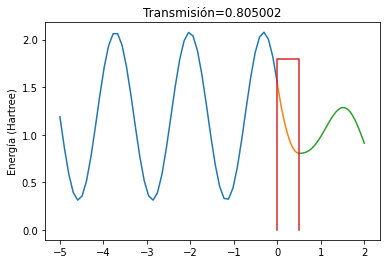

In [ ]:
BP(1.8,1.7,0.5)

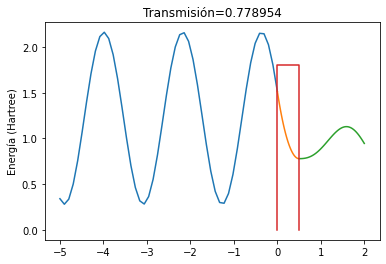

In [ ]:
BP(1.8,1.5,0.5)

### **Problema 1**

Un electrón con una energía de $2 \ eV$ encuentra una barrera con una altura de $5 \ eV$. ¿Cuál es la probabilidad de que el elecrón atraviese la barrera si esta tiene una amplitud de $1 \ nm$ (de $0.5 \ nm$)?

# $SISTEMAS \ \ PERTURBADOS$

Consideremos un sistema con ecuación de onda $\psi_n$ y cuyo hamiltoniano $H$ es independiente del tiempo. Si el tratamiento analítico de la ecuación de $Schr\ddot{o}dinger$: $H\psi_n=E\psi_n$, es muy complejo, es posible encontrar valores aproximados para las funciones propias y los valores propios de los estados estacionarios enlazantes, a través de la $\textbf{teoría de perturbaciones}$. Si asumimos que el Hamiltiniano $H$ de nuestro sistema es ligeramente diferente del Hamiltoniano $H^0$ de un sistema con función de onda $\psi_n^0$, cuya ecuación de $Schr\ddot{o}dinger$ es $H^0\psi_n^0=E^0\psi_n^0$, la cual sabemos resolver; podremos utilizar estás soluciones para aproximar el valor de $H$ de nuerstro sistema.

Si llamamos $\textbf{sistema sin perturbar}$ a aquel con Hamiltoniano $H^0$ y $\textbf{sistema perturbado}$ a aquel con Hamiltoniano $H$, tenemos que $H'=H-H^0$ es la $\textbf{perturbación}$ introducida a nuestro sistema, es decir, $H=H^0+H'$. Si asumimos que la perturbación se aplica gradualmente, es decir, $H=H^0+\lambda H'$ con $0\leq\lambda\leq 1$, podremos desarrollar $\psi_n$ y $E_n$ en series de Taylor y encontrar aproximaciones sucesivas para nuestro $\lambda$ de interes, es decir, $\lambda=1$. Para un sistema con niveles de energía no degenerados podemos expresar $\psi_n$ y $E_n$ como sigue:

$$\psi_n=\psi_n^0+\lambda \psi_n^1+\lambda^2\psi_n^2+...+\lambda^k\psi_n^k+... \ \ \ y \ \ \ E_n=E_n^0+\lambda E_n^1+\lambda^2 E_n^2+...+\lambda^kE_n^k+...$$

donde, $\psi_n^k=\frac{1}{k!}\frac{\partial^k\psi_n}{\partial\lambda^k}\mid_{\lambda=0}$ y $E_n^k=\frac{1}{k!}\frac{d^k E_n}{d\lambda^k}\mid_{\lambda=0}$ para $k\in \{1, 2, 3,...\}$. Las funciones $\psi_n^k$ y los valores $E_n^k$ se llaman $\textbf{correcciones de orden $k$}$ de la función de onda y de la energía. En el caso de la energía la corrección de primer orden se obtiene promediando la perturbación $H'$ sobre las correspondientes funciones de onda sin perturbar, es decir, $E_n¹=\langle \psi_n^0\mid H'\mid \psi_n^0 \rangle$. Por lo tanto la aproximación de primer orden a la energía está dada por:


$$E_n\simeq E_n^0+E_n^1=E_n^0+\int (\psi_n^0)^*H'\psi_n^0$$

En el caso de la función de onda la corrección de primer orden es $\psi_n^1=\sum_{m\neq n}\frac{\langle \psi_m^0\mid H'\mid \psi_n^0 \rangle}{E_n^0-E_m^0} \psi_m^0$. Así, la aproximación de primer orden para la función de onda $\psi_n$ es:

$$\psi_n\simeq \psi_n^0+\sum_{m\neq n}\frac{\langle \psi_m^0\mid H'\mid \psi_n^0 \rangle}{E_n^0-E_m^0}\psi_m^0$$

## **Particula en una caja 1-dimensional perturbada por una barrera de potencial**

Consideremos una partícula confinada en una caja 1-dimensional de longitud $l$, la cual está perturbada por una barrera de potencial de la forma $V(x)=V_0$ para $a\leq x\leq b$, donde $0\leq\ a<  b\leq l$. Graficamente la barrera de potencial es como se puede observar en la siguiente figura.

Text(0.5, 1.0, 'Barrera de potencial')

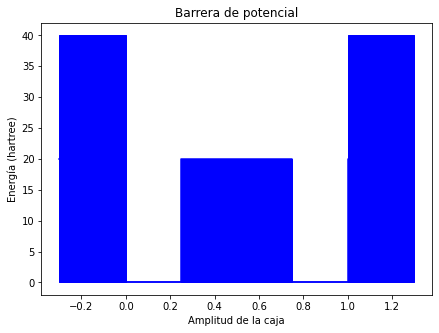

In [ ]:
# Parámetros generales del sistema

l = 1    # longitud de caja en bohrs
m = 1  # masa de la particula
h = 1  # hbar

# Parámetros adicionales para el sistema perturbado

V_0=20    # barrera de potencial
x1=0.25    # punto de inicio de barrera en proporcion de l
x2=0.75    # punto final de barrera en proporcion de l
iMax=5    # número de estados que contribuyen a la suma perturbativa
nmax=6    # número máximo de estados perturbados a ser calculados 

z=np.linspace(0,1,100) # variable que emplearemos para trabajar con matplotlib. En este caso z varia de 0 hasta l y el intervalo [0,l] queda dividido en 100 partes.

# Gráfico de la barrera de potencial

plt.figure(figsize=(7,5))
plt.plot([0,x1*l,x1*l,x2*l,x2*l,l],[0,0,V_0,V_0,0,0],c='b')
plt.plot([-0.3,0,0,l,l,l+0.3],[V_0,V_0,0,0,V_0,V_0],color='b')
plt.fill_between([-0.3,0],[2*V_0,2*V_0],color='b')
plt.fill_between([l,l+0.3],[2*V_0,2*V_0],color='b')
plt.fill_between([x1*l,x2*l],[V_0,V_0],color='b')
plt.xlabel('Amplitud de la caja')
plt.ylabel('Energía (hartree)')
plt.title('Barrera de potencial')

Para la energía la corrección de primer orden es
$E_n¹=\langle \psi_n^0\mid H'\mid \psi_n^0 \rangle=\langle \sqrt{\frac{2}{l}}sin(\frac{n\pi x}{l})\mid V(x)\mid\sqrt{\frac{2}{l}}sin(\frac{n\pi x}{l})\rangle=\frac{2V_0}{l}\int_a^b sin^2(\frac{n\pi x}{l})dx$. Por lo tanto la aproximación de primer orden para los valores de energía es:


$$E_n\simeq E_n^0+E_n^1=\frac{n²\pi²\hbar²}{2m_pl²}+\frac{2V_0}{l}\int_a^b sin^2(\frac{n\pi x}{l})dx$$

En el siguiente grafico se pueden comparar los valores de energía para un sistema sin perturbar y el sistema perturbado con una barrera de potencial de altura $V=20$ y amplitud $L=0.5$ (entre $0.25$ y $0.75$).

n= 1 ; E= 4.93480220054468 ; E.pert= 21.3009999242205
n= 2 ; E= 19.7392088021787 ; E.pert= 29.7392088021787
n= 3 ; E= 44.4132198049021 ; E.pert= 52.2911538970102
n= 4 ; E= 78.9568352087149 ; E.pert= 88.9568352087149
n= 5 ; E= 123.370055013617 ; E.pert= 134.643294558352
n= 6 ; E= 177.652879219608 ; E.pert= 187.652879219608


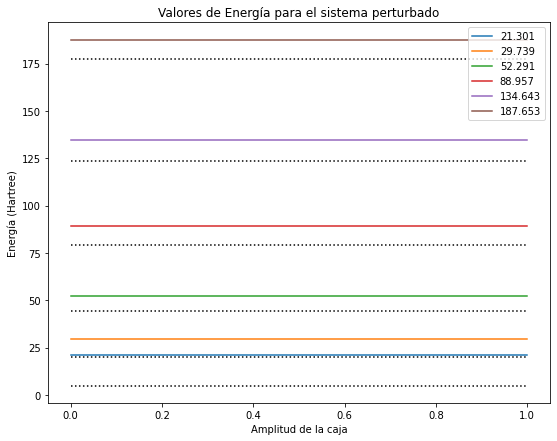

In [ ]:
# Parámetros generales del sistema

l = 1    # longitud de caja en bohrs
m = 1  # masa de la particula
h_b = 1  # hbar

# Parámetros adicionales para el sistema perturbado

V_0=20    # barrera de potencial
x1=0.25    # punto de inicio de barrera en proporcion de l
x2=0.75    # punto final de barrera en proporcion de l
iMax=5    # número de estados que contribuyen a la suma perturbativa
nmax=6    # número máximo de estados perturbados a ser calculados 

# Variables empleadas para el manejo del código

z=np.linspace(0,1,100) # variable que emplearemos para trabajar con matplotlib. En este caso z varia de 0 hasta l y el intervalo [0,l] queda dividido en 100 partes.

# Energías para el sistema perturbado

plt.figure(figsize=(9,7))
for n in range(1,nmax+1): 
    En=(((n**2)*(h_b**2)*(pi**2))/(2*m_p*l**2))
    Enp=((2*V_0)/l)*integrate(sin((n*pi*x)/l)**2,(x,x1*l,x2*l))
    Enpert=En+Enp
    print('n=',n,';','E=',En.evalf(),';','E.pert=',Enpert.evalf()) 
    plt.plot(z,Enpert+(z-z),label=round(Enpert.evalf(),3))
    plt.plot(z,En+(z-z),c='k',ls=':')
    plt.title('Valores de Energía para el sistema perturbado')
    plt.xlabel('Amplitud de la caja')
    plt.ylabel('Energía (Hartree)')
    plt.legend()

La corrección de primer orden para la función de onda $\psi_n$ es
$\sum_{m\neq n}\frac{\langle \psi_m⁰\mid H'\mid \psi_n⁰ \rangle}{E_n⁰-E_m⁰}\psi_m^0=\sum_{m\neq n}\frac{2m_pl^2}{\hbar^2\pi^2(n-m)(n+m)}\langle \psi_m^0\mid H'\mid \psi_n^0\rangle sin(\frac{m\pi x}{l})$.
Por lo tanto la aproximación de primer orden para la función de onda $\psi_n$ es:

$$\psi_n\simeq \psi_n^0+\sum_{m\neq n}\frac{\langle \psi_m⁰\mid H'\mid \psi_n⁰ \rangle}{E_n⁰-E_m⁰}\psi_m^0=\sqrt{\frac{2}{l}}sin(\frac{n\pi x}{l})+\sum_{m\neq n}\frac{2m_pl^2}{\hbar^2\pi^2(n-m)(n+m)}\langle \psi_m^0\mid H'\mid \psi_n^0\rangle sin(\frac{m\pi x}{l})$$

En las siguientes gráficas se comparan las funciones de onda de la partícula confinada en una caja 1-dimensional con las de la misma partícula bajo un potencial de perturbación en el trozo de la trayectoría que va desde $a=0.25$ hasta $b=0.75$.


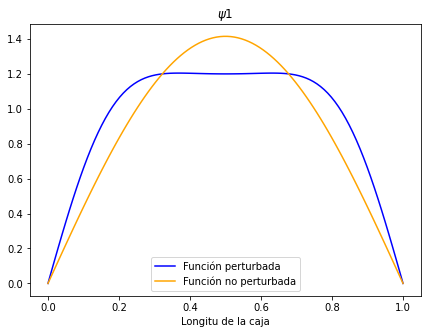

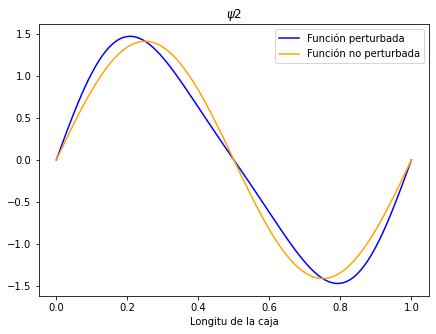

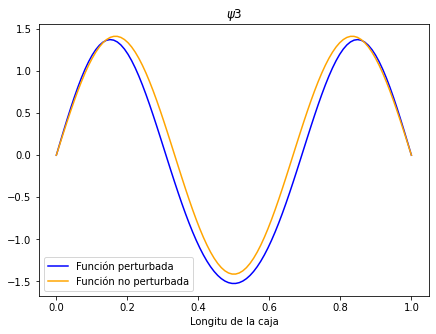

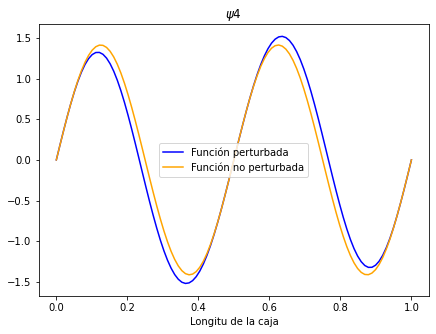

In [ ]:
plt.figure(figsize=(7,5))
GFOp(0.25,0.75,1,30,1)
plt.figure(figsize=(7,5))
GFOp(0.25,0.75,1,30,2)
plt.figure(figsize=(7,5))
GFOp(0.25,0.75,1,30,3)
plt.figure(figsize=(7,5))
GFOp(0.25,0.75,1,30,4)

Las funciones de densidad de probabilidad para la partícula perturbada tienen el siguiente aspecto:

In [ ]:
#@title
plt.figure(figsize=(7,5))
GFOd(0.25,0.75,1,30,1)
plt.figure(figsize=(7,5))
GFOd(0.25,0.75,1,30,2)
plt.figure(figsize=(7,5))
GFOd(0.25,0.75,1,30,3)
plt.figure(figsize=(7,5))
GFOd(0.25,0.75,1,30,4)

### Ejercicio 2

La función $GFOd(a,b,l,V,n)$ gráfica las funciones de densidad de probabilidad $|\psi_n|^2$ para una particula confinada en una caja $1$-dimensional de longitud $l$, la cual está sometida a un potencial de perturbación $V$ que va desde $a$ hasta $b$ ($0\leq a < b\leq l$.

1. Calcule $GFOd(0.25,0.75,2,20,1)$, $GFOd(0.1,0.2,2,20,1)$ y $GFOd(0.7,0.9,2,20,1)$ y describa los cambios que experimenta la función de densidad de probabilidad.
2. Repita el ítem anterior cambiando la altura de la barrera de potencial. ¿Qué cambios observa?

## BIBLIOGRAFÍA

Atkins, P. Physical Chemistry, Ed 8, WH Freeman, 2006.

McQuarrie D., Quantum Chemistry, Viva Books, 2016.